# EDA notebook: `athletes_with_target.parquet`

**How to use this with the report.** The report's findings carry IDs (F1, F2, ...). Each ID has a *deep dive* in Part B below with the evidence and visuals behind it. Part A is the step-by-step basics a data scientist does first: describe, check quality, look at each variable, then relationships and the target. Run top to bottom; all cells are self-contained and seeded.

**Finding index**

| ID | Finding | Deep dive |
|---|---|---|
| F1 | Most athletes skipped the lifts, survey and benchmarks | [F1](#F1) |
| F2 | Sentinel and impossible numeric values | [F2](#F2) |
| F3 | Leakage: the four lifts sum to the target | [F3](#F3) |
| F4 | Gender and weight drive total_lift | [F4](#F4) |
| F5 | Kept athletes are not typical (more male) | [F5](#F5) |
| F6 | 'Started with a coach' is negative, partly a gender confound | [F6](#F6) |
| F7 | Tiny lifts survive the cleaning filter | [F7](#F7) |
| F8 | Null and duplicate athlete ids | [F8](#F8) |
| F9 | Survey answers are messy multi-select text | [F9](#F9) |

**Part A: the basics** (A1 Description, A2 Quality, A3 Numeric, A4 Categorical, A5 Dates, A6 Correlations, A7 Target, A8 Time)

In [10]:
import os
DATA_PATH = '../data/interim/athletes_with_target.parquet'
TARGET, ID_COL, TIME_COL = 'total_lift', 'athlete_id', None
SEED = 0
NUM = ['athlete_id', 'age', 'height', 'weight', 'fran', 'helen', 'grace', 'filthy50', 'fgonebad', 'run400', 'run5k', 'candj', 'snatch', 'deadlift', 'backsq', 'pullups', 'total_lift']          # numeric columns
BIN = []          # binary columns
CAT = ['region', 'team', 'affiliate', 'gender', 'eat', 'train', 'background', 'experience', 'schedule', 'howlong']          # categorical columns
DT = []            # datetime columns (parsed in prep)
NUM_STR = []   # numeric stored as text (converted in prep)

In [11]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.max_columns", 60, "display.width", 160)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": .25})
np.random.seed(SEED)

def load(path):
    ext = os.path.splitext(path)[1].lower()
    if ext in (".csv", ".txt"): d = pd.read_csv(path, low_memory=False)
    elif ext == ".tsv": d = pd.read_csv(path, sep="\t", low_memory=False)
    elif ext in (".xlsx", ".xls", ".xlsm"): d = pd.read_excel(path)
    elif ext == ".parquet": d = pd.read_parquet(path)
    elif ext in (".json", ".jsonl"): d = pd.read_json(path, lines=ext == ".jsonl")
    else: raise ValueError(ext)
    return d.reset_index(drop=True)

def prep(d):
    for c in DT:
        if c in d: d[c] = pd.to_datetime(d[c], errors="coerce")
    for c in NUM_STR:
        if c in d: d[c] = pd.to_numeric(d[c].astype(str).str.replace(",", "", regex=False), errors="coerce")
    return d

def is_cls(y): return (not pd.api.types.is_numeric_dtype(y)) or y.nunique() <= 15
def sample(d, n=20000): return d if len(d) <= n else d.sample(n, random_state=SEED)
def show(title): print("=" * 8, title, "=" * 8)

In [12]:
df = prep(load(DATA_PATH))
print(df.shape)

ImportError: Unable to find a usable engine; tried using: 'pyarrow', 'fastparquet'.
A suitable version of pyarrow or fastparquet is required for parquet support.
Trying to import the above resulted in these errors:
 - `Import pyarrow` failed. pyarrow is required for parquet support. Use pip or conda to install the pyarrow package.
 - `Import fastparquet` failed. fastparquet is required for parquet support. Use pip or conda to install the fastparquet package.

## A1. What is in the data?
Shape, a few raw rows, dtypes, and basic numeric statistics. Look for columns that should not be the dtype they are, and for impossible min/max values.

In [ ]:
show("shape / memory"); print(df.shape, f"{df.memory_usage(deep=True).sum()/1e6:.1f} MB")
show("first rows"); display(df.head(8))
show("dtypes"); display(df.dtypes.to_frame("dtype").join(df.nunique().rename("unique")).join(df.isna().mean().mul(100).round(2).rename("missing_%")))
show("numeric summary"); display(df[NUM].describe(percentiles=[.01,.25,.5,.75,.99]).T) if NUM else print("no numeric columns")

======== shape / memory ========


(423006, 27) 257.0 MB
======== first rows ========


,athlete_id,region,team,affiliate,gender,age,height,weight,fran,helen,grace,filthy50,fgonebad,run400,run5k,candj,snatch,deadlift,backsq,pullups,eat,train,background,experience,schedule,howlong,total_lift
0,2554.0,South West,Double Edge,Double Edge CrossFit,Male,24.0,70.0,166.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,220.0,NaN,400.0,305.0,NaN,None,I workout mostly at a CrossFit Affiliate|I hav...,I played youth or high school level sports|I r...,I began CrossFit with a coach (e.g. at an affi...,I do multiple workouts in a day 2x a week|,4+ years|,NaN
1,3517.0,None,None,None,Male,42.0,70.0,190.0,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None,I have a coach who determines my programming|I...,I played youth or high school level sports|,I began CrossFit with a coach (e.g. at an affi...,I do multiple workouts in a day 2x a week|,4+ years|,NaN
2,4691.0,None,None,None,None,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None,None,None,None,None,None,NaN
3,5164.0,Southern California,LAX CrossFit,LAX CrossFit,Male,40.0,67.0,NaN,211.0,645.0,300.0,NaN,196.0,NaN,NaN,245.0,200.0,375.0,325.0,25.0,I eat 1-3 full cheat meals per week|,I workout mostly at a CrossFit Affiliate|I hav...,I played youth or high school level sports|,I began CrossFit by trying it alone (without a...,I usually only do 1 workout a day|,4+ years|,1145.0
4,5286.0,None,None,None,Male,32.0,65.0,149.0,206.0,465.0,NaN,1053.0,NaN,NaN,1081.0,205.0,150.0,NaN,325.0,50.0,I eat quality foods but don't measure the amount|,I workout mostly at a CrossFit Affiliate|I inc...,I played college sports|,I began CrossFit by trying it alone (without a...,I usually only do 1 workout a day|I strictly s...,1-2 years|,NaN
5,6491.0,None,None,None,Male,37.0,73.0,230.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,265.0,200.0,435.0,414.0,NaN,I eat strict Paleo|,I workout mostly at a CrossFit Affiliate|I rec...,I played youth or high school level sports|,I began CrossFit by trying it alone (without a...,I usually only do 1 workout a day|I typically ...,4+ years|,1314.0
6,6610.0,South Central,Get Lifted,Get Lifted CrossFit,Male,21.0,72.0,175.0,NaN,NaN,NaN,NaN,0.0,NaN,NaN,0.0,0.0,0.0,0.0,0.0,I eat quality foods but don't measure the amou...,I workout mostly at a CrossFit Affiliate|I hav...,I have no athletic background besides CrossFit|,I began CrossFit with a coach (e.g. at an affi...,I do multiple workouts in a day 3+ times a wee...,2-4 years|,0.0
7,7268.0,None,None,None,None,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None,None,None,None,None,None,NaN


======== dtypes ========


,dtype,unique,missing_%
athlete_id,float64,423003,0.00
region,object,17,40.60
team,object,4532,63.32
affiliate,object,9778,42.81
gender,object,3,21.72
age,float64,52,21.72
height,float64,127,62.21
weight,float64,386,45.65
fran,float64,1041,86.90
helen,float64,1064,92.84


======== numeric summary ========


,count,mean,std,min,1%,25%,50%,75%,99%,max
athlete_id,423003.0,292748.166538,1.849697e+05,82.0,6502.02,135091.5,275839.0,473188.0,620322.98,6.330830e+05
age,331110.0,32.516750,7.730671e+00,13.0,18.00,27.0,31.0,37.0,53.00,1.250000e+02
height,159869.0,120.621684,2.097995e+04,0.0,36.00,66.0,69.0,72.0,77.00,8.388607e+06
weight,229890.0,170.896137,5.837980e+01,1.0,105.00,145.0,170.0,192.0,260.00,2.017500e+04
fran,55426.0,988.669054,7.200430e+04,1.0,133.00,215.0,290.0,392.0,794.75,8.388607e+06
helen,30279.0,1207.950230,6.824091e+04,1.0,405.00,525.0,595.0,694.0,1110.00,8.388607e+06
grace,40745.0,576.602454,4.891145e+04,-60.0,85.00,149.0,193.0,262.0,648.00,8.388607e+06
filthy50,19359.0,2127.862596,6.055021e+04,1.0,877.58,1308.0,1550.0,1809.0,3000.00,8.388607e+06
fgonebad,29738.0,1472.252001,9.762688e+04,0.0,0.00,240.0,294.0,336.0,471.00,8.388607e+06
run400,22246.0,524.127888,5.628804e+04,1.0,49.00,62.0,71.0,84.0,3120.00,8.388607e+06


## A2. Data quality: missing values and duplicates
Where is data missing, and is the pattern random? Check duplicates and key integrity before trusting any statistic.

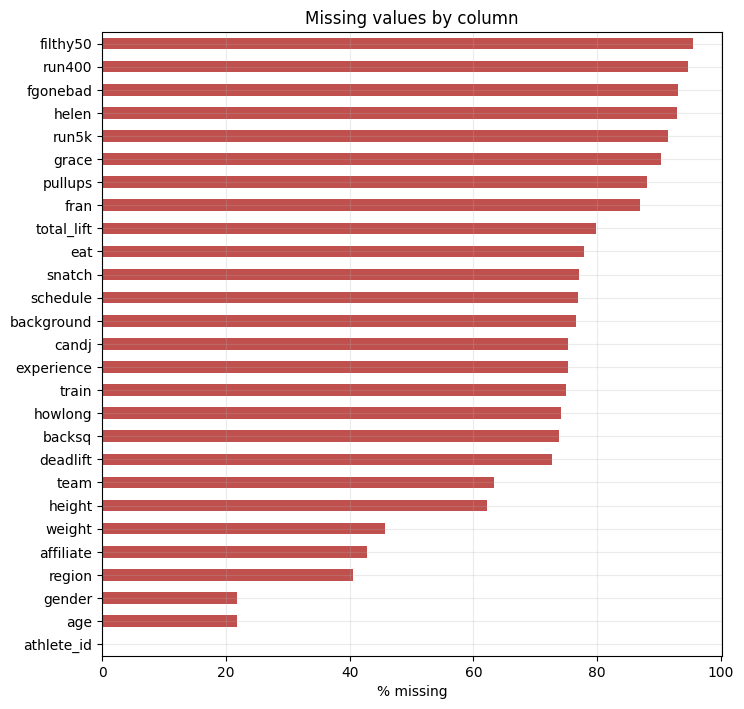

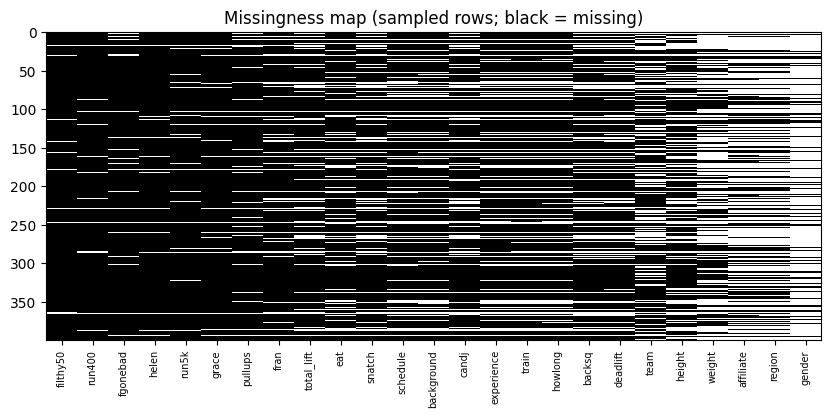

Exact duplicate rows: 2 (0.00%)
Duplicate values in key 'athlete_id': 2


In [ ]:
m = df.isna().mean().mul(100).sort_values(ascending=False)
m = m[m > 0]
if len(m):
    fig, ax = plt.subplots(figsize=(8, max(2.5, .3*min(len(m), 30))))
    m.head(30)[::-1].plot.barh(ax=ax, color="#c0504d"); ax.set_xlabel("% missing"); ax.set_title("Missing values by column")
    plt.show()
    cols = list(m.index[:25])
    if len(cols) > 1:
        s = sample(df, 400)[cols].isna().astype(int)
        fig, ax = plt.subplots(figsize=(10, 4)); ax.imshow(s.values, aspect="auto", cmap="Greys", interpolation="nearest")
        ax.set_xticks(range(len(cols))); ax.set_xticklabels(cols, rotation=90, fontsize=7); ax.set_title("Missingness map (sampled rows; black = missing)"); ax.grid(False)
        plt.show()
else:
    print("No NaN values.")
d = int(df.duplicated().sum()); print(f"Exact duplicate rows: {d} ({d/len(df):.2%})")
if ID_COL: print(f"Duplicate values in key {ID_COL!r}: {int(df[ID_COL].duplicated().sum())}")

## A3. Numeric columns, one at a time
Shape of each distribution: skew, spikes, long tails, zero inflation. These decide transforms and outlier handling.

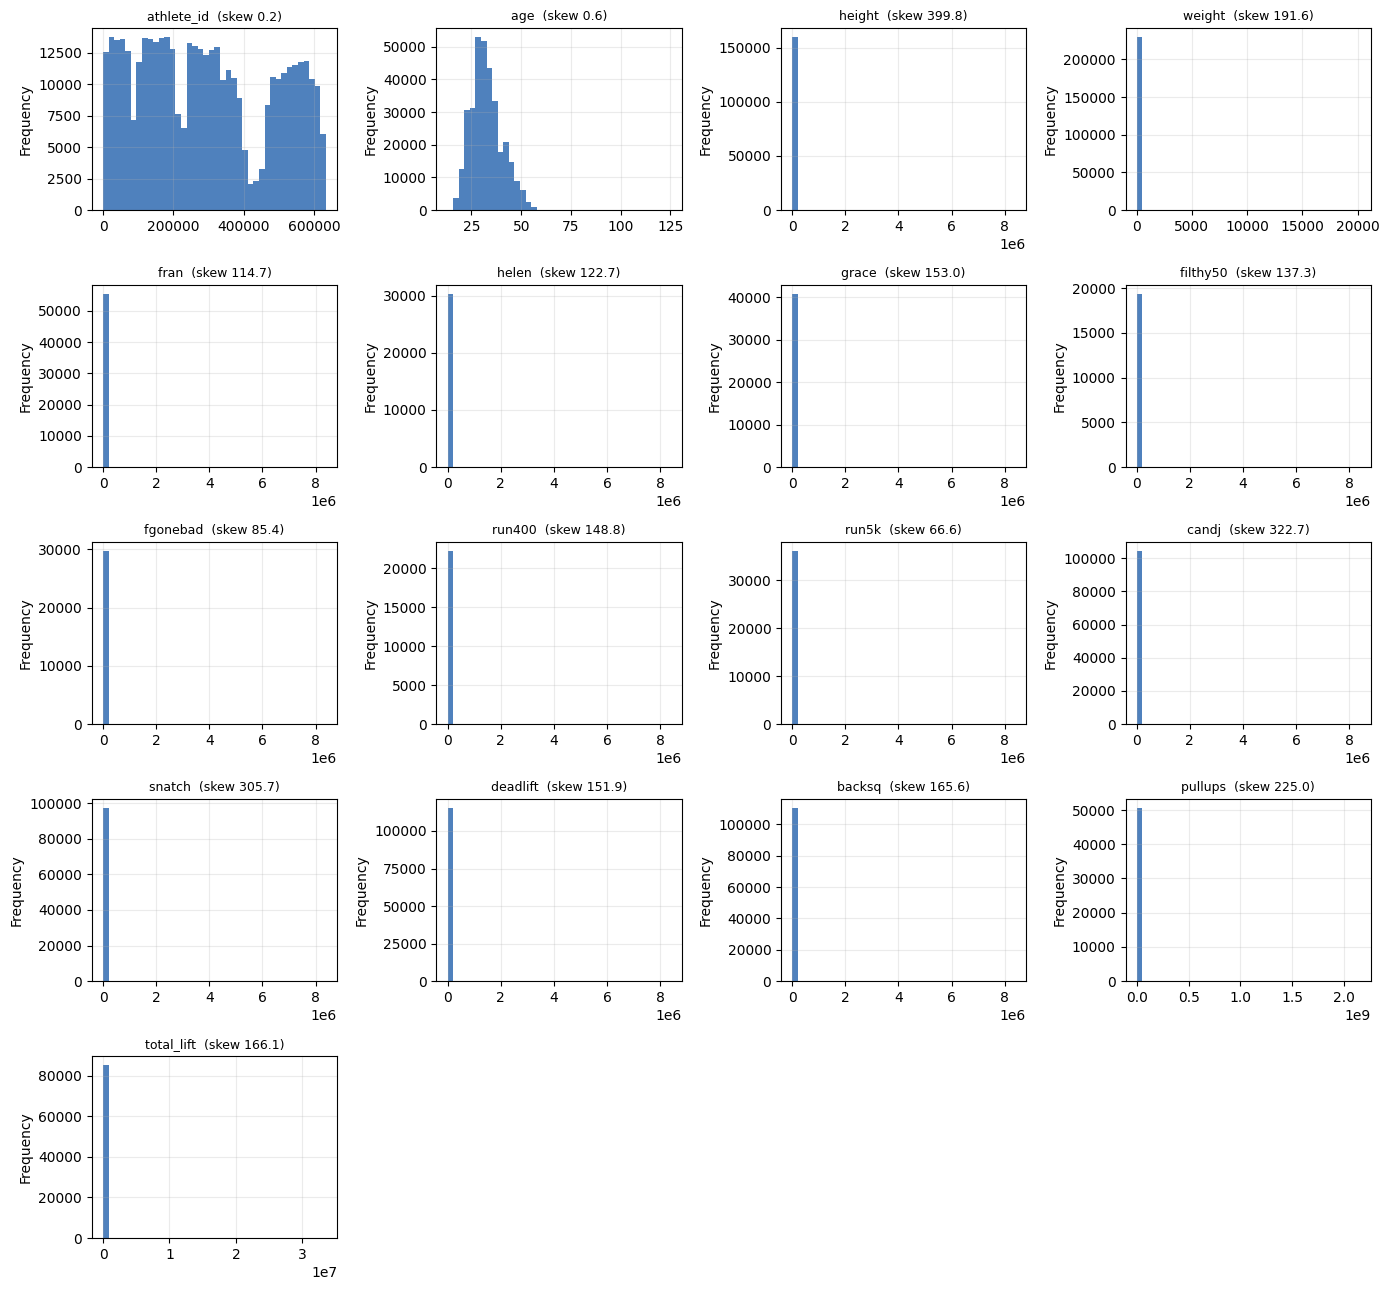

In [ ]:
cols = NUM[:24]
if cols:
    nc = 4; nr = -(-len(cols)//nc)
    fig, axs = plt.subplots(nr, nc, figsize=(14, 2.6*nr)); axs = np.atleast_1d(axs).ravel()
    for ax, c in zip(axs, cols):
        df[c].dropna().plot.hist(bins=40, ax=ax, color="#4f81bd"); ax.set_title(f"{c}  (skew {df[c].skew():.1f})", fontsize=9)
    for ax in axs[len(cols):]: ax.axis("off")
    plt.tight_layout(); plt.show()
    if len(NUM) > 24: print(f"{len(NUM)-24} more numeric columns not plotted; see deep dives or edit `cols`.")

## A4. Categorical columns
Level counts. Look for dominant levels, rare levels, and label variants that should be merged.

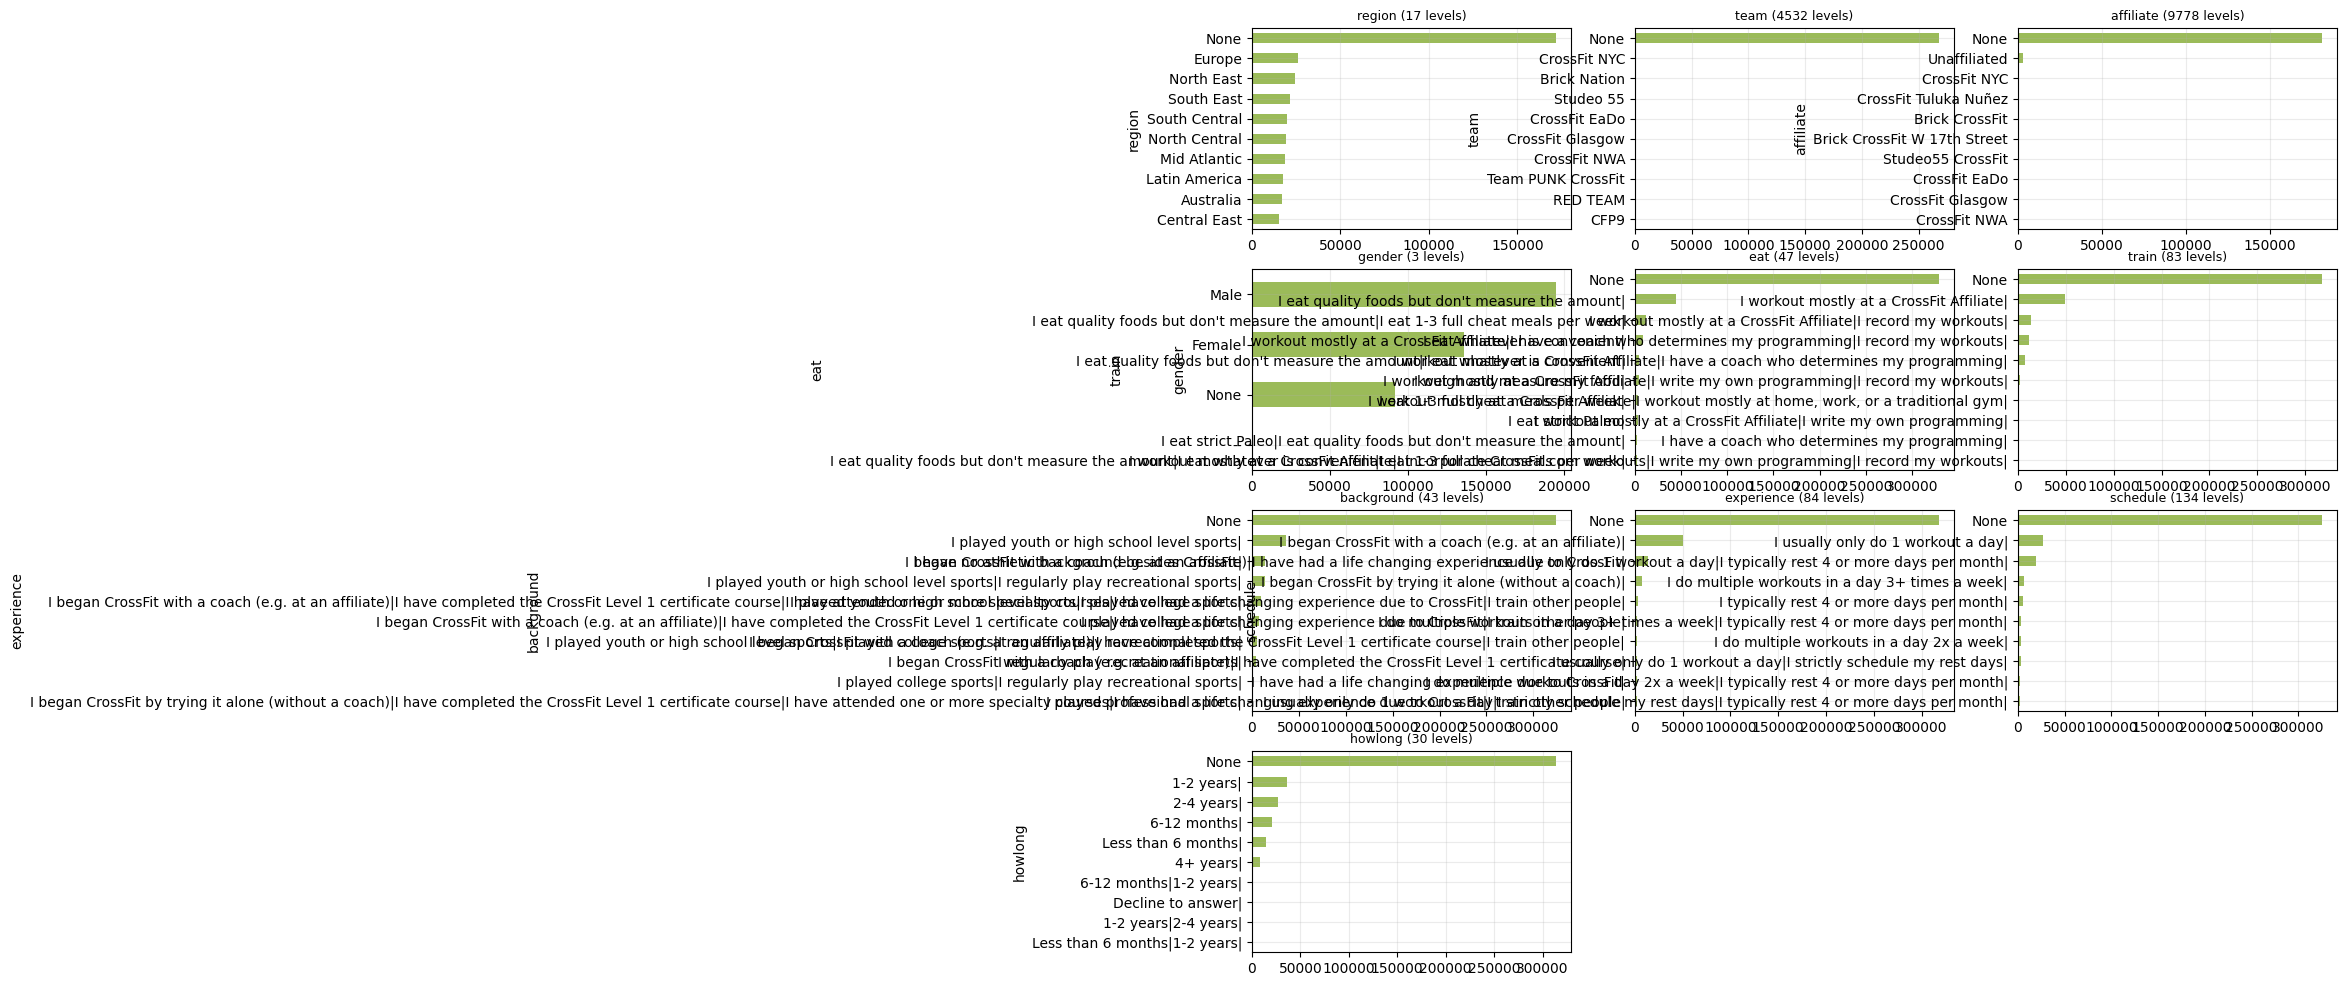

In [ ]:
cols = [c for c in CAT + BIN if df[c].nunique() > 1][:12]
if cols:
    nc = 3; nr = -(-len(cols)//nc)
    fig, axs = plt.subplots(nr, nc, figsize=(14, 3*nr)); axs = np.atleast_1d(axs).ravel()
    for ax, c in zip(axs, cols):
        vc = df[c].value_counts(dropna=False).head(10)
        vc[::-1].plot.barh(ax=ax, color="#9bbb59"); ax.set_title(f"{c} ({df[c].nunique()} levels)", fontsize=9)
    for ax in axs[len(cols):]: ax.axis("off")
    plt.tight_layout(); plt.show()

## A5. Dates
Volume over time. Sudden drops or spikes usually mean pipeline or definition changes.

In [ ]:
for c in DT[:4]:
    s = df[c].dropna()
    if len(s):
        fig, ax = plt.subplots(figsize=(10, 2.6)); s.dt.to_period("M").value_counts().sort_index().plot(ax=ax, marker="o", ms=3)
        ax.set_title(f"Rows per month by {c}"); plt.show()

## A6. How numeric columns relate to each other
Rank correlation (robust to outliers and monotone transforms). Strongly related pairs are redundant for many models.

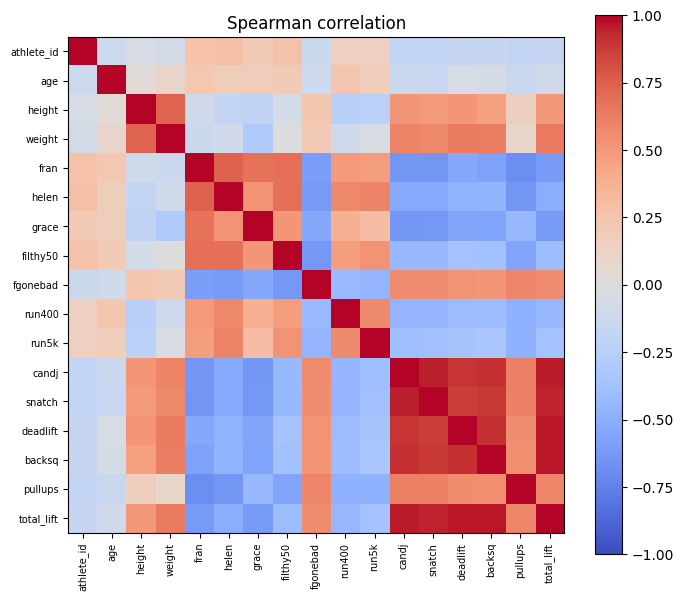

,level_0,level_1,rho
134,backsq,total_lift,0.968146
132,deadlift,total_lift,0.963200
125,candj,total_lift,0.960780
121,candj,snatch,0.949893
129,snatch,total_lift,0.942549
130,deadlift,backsq,0.914023
123,candj,backsq,0.908801
122,candj,deadlift,0.892636
127,snatch,backsq,0.888082
126,snatch,deadlift,0.865935


In [ ]:
use = NUM[:40]
if len(use) >= 2:
    cm = df[use].corr(method="spearman")
    fig, ax = plt.subplots(figsize=(8, 7)); im = ax.imshow(cm.values, cmap="coolwarm", vmin=-1, vmax=1); ax.grid(False)
    ax.set_xticks(range(len(use))); ax.set_yticks(range(len(use))); ax.set_xticklabels(use, rotation=90, fontsize=7); ax.set_yticklabels(use, fontsize=7)
    fig.colorbar(im); ax.set_title("Spearman correlation"); plt.show()
    pairs = cm.where(np.triu(np.ones(cm.shape), 1).astype(bool)).stack().rename("rho").reset_index()
    pairs["abs"] = pairs.rho.abs(); display(pairs.sort_values("abs", ascending=False).head(10).drop(columns="abs"))

## A7. The target
Target distribution, then the features most related to it. Treat very strong relationships with suspicion until the leakage check in Part B.

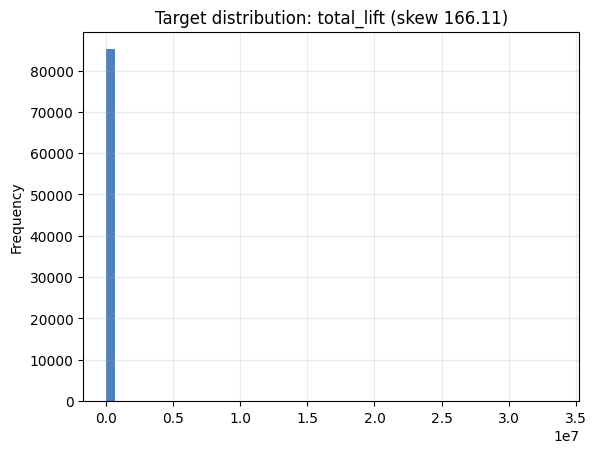

,feature,|spearman|
14,backsq,0.968146
13,deadlift,0.963200
11,candj,0.960780
12,snatch,0.942549
3,weight,0.636936
4,fran,0.621284
6,grace,0.616652
15,pullups,0.590770
8,fgonebad,0.555421
5,helen,0.508347


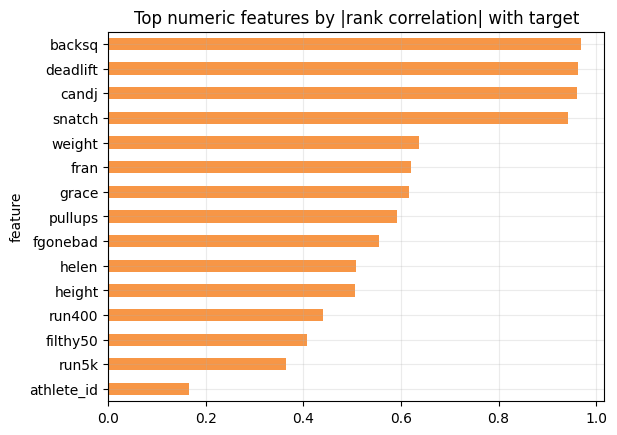

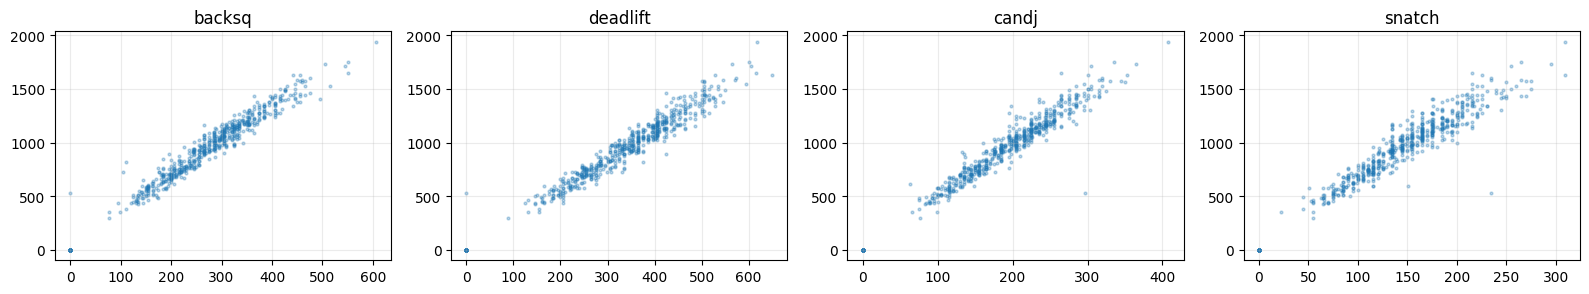

In [ ]:
if TARGET:
    y = df[TARGET]
    if is_cls(y):
        vc = y.value_counts(dropna=False); display(vc.to_frame("count").assign(share=lambda t: (t["count"]/t["count"].sum()).round(4)))
        vc.plot.bar(color="#4f81bd"); plt.title(f"Target distribution: {TARGET}"); plt.show()
        yc = y.astype("category").cat.codes.where(y.notna())
    else:
        y.dropna().plot.hist(bins=50, color="#4f81bd"); plt.title(f"Target distribution: {TARGET} (skew {y.skew():.2f})"); plt.show(); yc = y
    rows = []
    for c in NUM + BIN:
        if c == TARGET: continue
        x = df[c]; ok = x.notna() & yc.notna()
        if ok.sum() > 20 and x[ok].nunique() > 1: rows.append((c, abs(x[ok].rank().corr(pd.Series(yc)[ok].rank()))))
    r = pd.DataFrame(rows, columns=["feature", "|spearman|"]).sort_values("|spearman|", ascending=False).head(15)
    display(r); r[::-1].set_index("feature").plot.barh(legend=False, color="#f79646"); plt.title("Top numeric features by |rank correlation| with target"); plt.show()
    top = list(r.feature.head(4))
    if top:
        fig, axs = plt.subplots(1, len(top), figsize=(4*len(top), 3.2)); axs = np.atleast_1d(axs)
        for ax, c in zip(axs, top):
            if is_cls(y): df.boxplot(column=c, by=TARGET, ax=ax); ax.set_title(c); ax.set_xlabel(TARGET)
            else: s = sample(df, 3000); ax.scatter(s[c], s[TARGET], s=4, alpha=.3); ax.set_title(c)
        plt.suptitle(""); plt.tight_layout(); plt.show()
else:
    print("No target specified; skipping.")

## A8. Time structure
Does the data or target change over time? If so, random splits will be over-optimistic.

In [ ]:
if TIME_COL:
    t = df[TIME_COL]; per = t.dt.to_period("M")
    fig, axs = plt.subplots(1, 2 if TARGET else 1, figsize=(13, 3)); axs = np.atleast_1d(axs)
    per.value_counts().sort_index().plot(ax=axs[0], marker="o", ms=3); axs[0].set_title("Rows per month")
    if TARGET and pd.api.types.is_numeric_dtype(df[TARGET]):
        df.groupby(per)[TARGET].mean().plot(ax=axs[1], marker="o", ms=3); axs[1].set_title(f"Mean {TARGET} per month")
    plt.tight_layout(); plt.show()
    half = t.median(); e, l = df[t <= half], df[t > half]
    sh = {c: (l[c].mean() - e[c].mean())/df[c].std() for c in NUM if c != TIME_COL and df[c].std() > 0}
    display(pd.Series(sh, name="std mean shift (late vs early)").sort_values(key=abs, ascending=False).head(10).to_frame())
else:
    print("No time column specified; skipping.")

No time column specified; skipping.


# Part B: Deep dives on the report's findings
Each section is anchored by the finding ID used in the report.

In [ ]:

# --- setup for the custom cells: rebuild the cleaned data the pipeline actually uses ---
import sys
from pathlib import Path
_root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "prepare_features.py").exists())
sys.path.insert(0, str(_root / "src"))
from config import LIFTS, RAW_CSV
from prepare_features import clean, build_features
raw = pd.read_csv(RAW_CSV, low_memory=False)
raw["total_lift"] = raw[LIFTS].sum(axis=1, min_count=4)
final = clean(raw)
cdf = final.merge(build_features(final), on="athlete_id", suffixes=("_raw", ""))
cdf["total_lift"] = cdf[LIFTS].sum(axis=1)
SURVEY = ["eat", "train", "background", "experience", "schedule", "howlong"]
print("raw", len(raw), "-> cleaned", len(cdf))


raw 423006 -> cleaned 30074


<a id="F1"></a>
## F1. Most athletes skipped the lifts, survey and benchmarks
**Type:** missing &nbsp; **Columns:** `deadlift`, `candj`, `eat`, `fran`

Only 20% have all four lifts, ~24% answered the survey, benchmark workouts are 87-95% empty. Extra cells show the row waterfall 423k -> 30k.

In [ ]:
cols = [c for c in ['deadlift', 'candj', 'eat', 'fran'] if c in df]
for c in cols:
    print(f"{c}: {df[c].isna().mean():.1%} missing")
    if TARGET and is_cls(df[TARGET]):
        yy = df[TARGET].astype("category").cat.codes.where(df[TARGET].notna())
        display(yy.groupby(df[c].isna()).agg(["mean", "count"]).rename(index={False: "present", True: "missing"}).round(3))
    if TIME_COL:
        fig, ax = plt.subplots(figsize=(10, 2.6)); df[c].isna().groupby(df[TIME_COL].dt.to_period("M")).mean().mul(100).plot(ax=ax, marker="o", ms=3)
        ax.set_title(f"% missing in {c} over time"); plt.show()

deadlift: 72.7% missing
candj: 75.3% missing
eat: 77.8% missing
fran: 86.9% missing


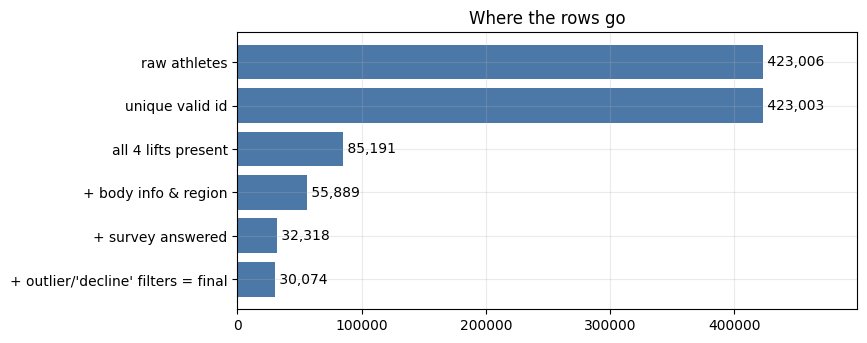

,avg share filled
body,0.622
lifts,0.253
survey,0.241
benchmarks,0.084


In [ ]:

# Row waterfall: where do the 423k athletes go?
d = raw.dropna(subset=["athlete_id"]).drop_duplicates("athlete_id"); steps = [("raw athletes", len(raw)), ("unique valid id", len(d))]
d = d.dropna(subset=LIFTS); steps.append(("all 4 lifts present", len(d)))
d = d.dropna(subset=["region", "age", "weight", "height", "gender"]); steps.append(("+ body info & region", len(d)))
d = d.dropna(subset=["eat", "background", "experience", "schedule", "howlong"]); steps.append(("+ survey answered", len(d)))
steps.append(("+ outlier/'decline' filters = final", len(cdf)))
names, vals = zip(*steps); fig, ax = plt.subplots(figsize=(8, 3.6)); ax.barh(names[::-1], vals[::-1], color="#4c78a8")
[ax.text(v, i, f" {v:,}", va="center") for i, v in enumerate(vals[::-1])]; ax.set_xlim(0, max(vals)*1.18); ax.set_title("Where the rows go"); plt.show()
groups = {"body": ["gender","age","height","weight"], "lifts": LIFTS, "survey": SURVEY,
          "benchmarks": ["fran","helen","grace","filthy50","fgonebad","run400","run5k","pullups"]}
display(pd.Series({k: raw[v].notna().mean().mean() for k, v in groups.items()}, name="avg share filled").round(3).to_frame())


<a id="F2"></a>
## F2. Sentinel and impossible numeric values
**Type:** distribution &nbsp; **Columns:** `height`, `deadlift`

33 cells equal 8,388,607 (2^23-1); ages of 125, heights of 0 or 8 million inches, zero/negative lifts. Raw target skew is 166.

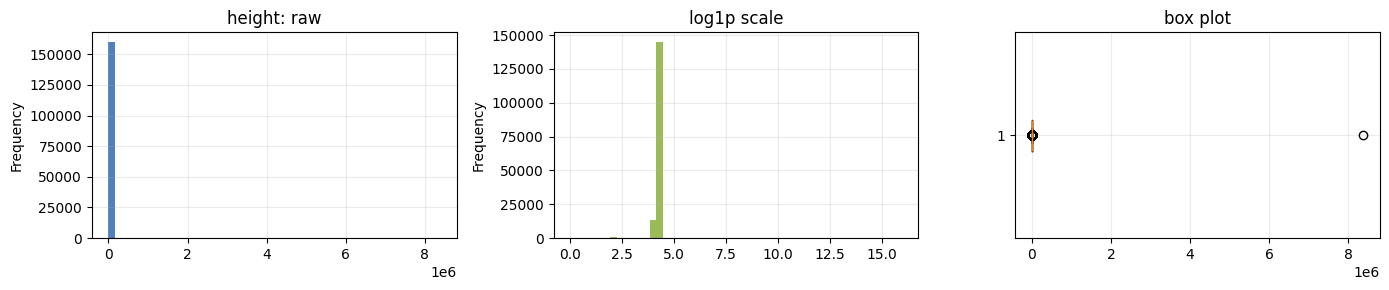

IQR outliers: 1842 (0.4%); thresholds [57, 81]


,athlete_id,region,team,affiliate,gender,age,height,weight,fran,helen,grace,filthy50,fgonebad,run400,run5k,candj,snatch,deadlift,backsq,pullups,eat,train,background,experience,schedule,howlong,total_lift
67446,163080.0,Australia,CrossFit Morley,CrossFit Morley,Male,25.0,8388607.0,187.0,3600.0,3600.0,3600.0,3600.0,1.0,3600.0,3600.0,2.0,2.0,2.0,2.0,1.0,I eat whatever is convenient|I eat 1-3 full ch...,I workout mostly at a CrossFit Affiliate|,I played youth or high school level sports|,I began CrossFit with a coach (e.g. at an affi...,I usually only do 1 workout a day|,1-2 years|,8.0
361003,193379.0,None,None,None,Male,34.0,7087.0,198.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None,None,None,None,None,None,NaN
382676,185167.0,None,None,None,Male,26.0,787.0,243.0,NaN,NaN,310.0,NaN,NaN,NaN,NaN,187.0,154.0,397.0,243.0,NaN,I eat quality foods but don't measure the amount|,I workout mostly at a CrossFit Affiliate|,I played youth or high school level sports|I p...,I began CrossFit with a coach (e.g. at an affi...,I typically rest 4 or more days per month|,1-2 years|,981.0
29607,10624.0,None,None,None,Male,29.0,748.0,110.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,441.0,220.0,20.0,I eat whatever is convenient|,I workout mostly at a CrossFit Affiliate|,I played youth or high school level sports|I p...,I began CrossFit with a coach (e.g. at an affi...,I usually only do 1 workout a day|,Less than 6 months|1-2 years|,NaN
122814,318112.0,Australia,MANA,CrossFit Mana,Male,27.0,744.0,165.0,374.0,NaN,NaN,NaN,NaN,NaN,NaN,187.0,132.0,276.0,254.0,NaN,None,None,None,None,None,None,849.0
374476,101982.0,None,None,None,Male,29.0,740.0,227.0,521.0,NaN,NaN,1550.0,296.0,NaN,1767.0,198.0,154.0,309.0,265.0,15.0,I eat quality foods but don't measure the amount|,I have a coach who determines my programming|I...,I played youth or high school level sports|I r...,I began CrossFit with a coach (e.g. at an affi...,I do multiple workouts in a day 3+ times a week|,1-2 years|,926.0
110804,482866.0,Australia,CrossFit Mt Eden,CrossFit Mt. Eden,Male,32.0,732.0,180.0,500.0,NaN,NaN,NaN,NaN,NaN,2100.0,183.0,117.0,331.0,309.0,21.0,None,None,None,None,None,None,940.0
132676,498636.0,Africa,None,CrossFit Pretoria,Male,21.0,732.0,227.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None,None,None,None,None,None,NaN


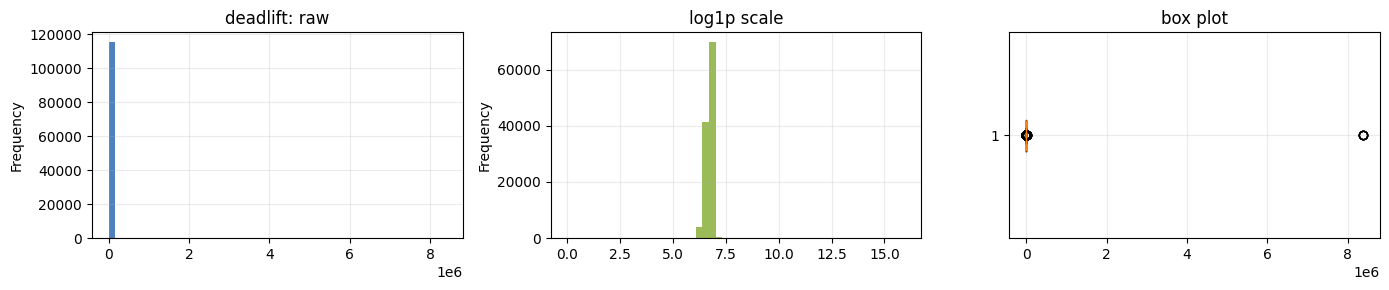

IQR outliers: 3899 (0.9%); thresholds [15, 655]


,athlete_id,region,team,affiliate,gender,age,height,weight,fran,helen,grace,filthy50,fgonebad,run400,run5k,candj,snatch,deadlift,backsq,pullups,eat,train,background,experience,schedule,howlong,total_lift
66525,111989.0,Central East,CrossFit Knights,CrossFit Knights,Male,19.0,78.0,210.0,2.0,120.0,4.0,NaN,NaN,7.0,420.0,5000.0,95.0,8388607.0,8388607.0,1.0,I weigh and measure my food|I eat strict Paleo|,I workout mostly at a CrossFit Affiliate|,I regularly play recreational sports|,I began CrossFit by trying it alone (without a...,I strictly schedule my rest days|,2-4 years|,16782309.0
169658,28883.0,Australia,BTS CrossFit,BTS CrossFit,Female,38.0,68.0,165.0,300000.0,7200.0,10528.0,NaN,1.0,NaN,8388607.0,11.0,2.0,8388607.0,1984.0,500000.0,I eat quality foods but don't measure the amount|,I have a coach who determines my programming|,I have no athletic background besides CrossFit|,I began CrossFit with a coach (e.g. at an affi...,I usually only do 1 workout a day|,2-4 years|,8390604.0
88473,164631.0,South Central,CrossFit Jääkarhu,CrossFit Jaakarhu,Male,30.0,72.0,214.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,8388607.0,8388607.0,8388607.0,8388607.0,NaN,None,I workout mostly at a CrossFit Affiliate|I hav...,I played college sports|,I began CrossFit with a coach (e.g. at an affi...,I do multiple workouts in a day 3+ times a week|,1-2 years|,33554428.0
279879,292835.0,Southern California,CrossFit Escondido,CrossFit Escondido,Male,27.0,75.0,215.0,NaN,NaN,NaN,NaN,10000.0,NaN,NaN,5000.0,5001.0,8388607.0,8388607.0,7000.0,None,None,None,None,None,None,16787215.0
281407,200349.0,None,None,None,Male,22.0,NaN,183.0,230.0,NaN,NaN,NaN,NaN,NaN,1140.0,235.0,185.0,8388607.0,8388607.0,NaN,None,None,None,None,None,None,16777634.0
241680,566733.0,South East,CrossFit SteadFast,CrossFit SteadFast,Female,26.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1500.0,NaN,18000.0,135000.0,NaN,I eat strict Paleo|,I workout mostly at a CrossFit Affiliate|,I have no athletic background besides CrossFit|,I began CrossFit with a coach (e.g. at an affi...,I typically rest 4 or more days per month|,Less than 6 months|,NaN
8051,40813.0,None,None,None,Male,24.0,68.0,195.0,77.0,178.0,79.0,50.0,8388607.0,29.0,563.0,6000.0,5000.0,10000.0,8000.0,99999.0,None,None,None,None,None,None,29000.0
78719,153366.0,Europe,CrossFit Cheltenham,CrossFit Cheltenham,Male,20.0,69.0,156.0,195.0,NaN,82.0,NaN,NaN,NaN,NaN,999.0,998.0,10000.0,10.0,300.0,None,None,None,None,None,None,12007.0


In [ ]:
for c in [c for c in ['height', 'deadlift'] if c in df and pd.api.types.is_numeric_dtype(df[c])]:
    s = df[c].dropna(); q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    lo, hi = q1 - 1.5*iqr, q3 + 1.5*iqr
    fig, axs = plt.subplots(1, 3, figsize=(14, 3))
    s.plot.hist(bins=50, ax=axs[0], color="#4f81bd"); axs[0].set_title(f"{c}: raw")
    (np.log1p(s - s.min()) if s.min() < 0 else np.log1p(s)).plot.hist(bins=50, ax=axs[1], color="#9bbb59"); axs[1].set_title("log1p scale")
    axs[2].boxplot(s, vert=False, showfliers=True); axs[2].set_title("box plot"); plt.tight_layout(); plt.show()
    out = df[(df[c] < lo) | (df[c] > hi)]; print(f"IQR outliers: {len(out)} ({len(out)/len(df):.1%}); thresholds [{lo:.4g}, {hi:.4g}]")
    display(out.sort_values(c, ascending=False).head(8))

In [ ]:

# Sentinel values: exactly 8,388,607 (2^23-1) and 2,147,483,647 (2^31-1)
num = raw.select_dtypes("number").drop(columns=["athlete_id", "total_lift"])
display(pd.Series({c: int((raw[c] == 8388607).sum()) for c in num if (raw[c] == 8388607).any()}, name="cells == 8388607").to_frame())
print("pullups == 2147483647:", int((raw.pullups == 2147483647).sum()))
print("age<18:", int((raw.age < 18).sum()), "| age>80:", int((raw.age > 80).sum()),
      "| height outside 48-96in:", int(((raw.height < 48) | (raw.height > 96)).sum()),
      "| weight <50 or >1500:", int(((raw.weight < 50) | (raw.weight > 1500)).sum()))
print("lifts <= 0:", {c: int((raw[c] <= 0).sum()) for c in LIFTS})
print(f"total_lift skew raw {raw.total_lift.skew():.1f} -> cleaned {cdf.total_lift.skew():.2f}")


,cells == 8388607
height,1
fran,4
helen,2
grace,1
filthy50,1
fgonebad,4
run400,1
run5k,8
candj,1
snatch,1


pullups == 2147483647: 1
age<18: 1576 | age>80: 8 | height outside 48-96in: 1692 | weight <50 or >1500: 121
lifts <= 0: {'deadlift': 3689, 'candj': 3384, 'snatch': 3312, 'backsq': 3508}
total_lift skew raw 166.1 -> cleaned -0.10


<a id="F3"></a>
## F3. Leakage: the four lifts sum to the target
**Type:** leakage &nbsp; **Columns:** `deadlift`, `backsq`, `candj`, `snatch`

Spearman 0.94-0.97 with total_lift because total_lift is their sum. Extra cells show R2 with vs without them.

Suspect: deadlift.  Ask: is this value known at prediction time? Is it derived from / recorded after total_lift?


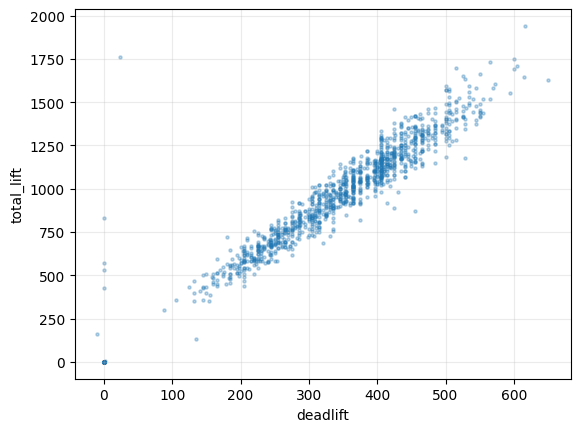

Exact equality share: 0.0064
Suspect: backsq.  Ask: is this value known at prediction time? Is it derived from / recorded after total_lift?


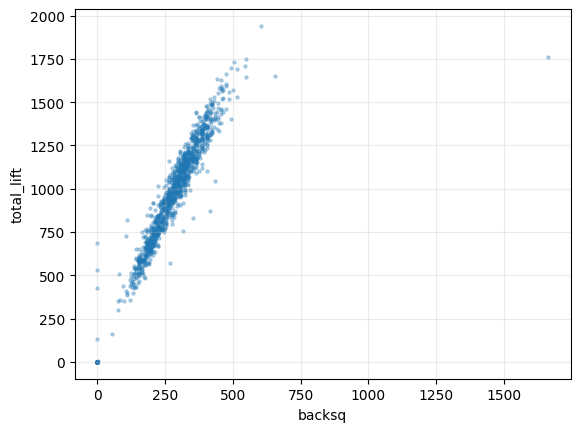

Exact equality share: 0.0064
Suspect: candj.  Ask: is this value known at prediction time? Is it derived from / recorded after total_lift?


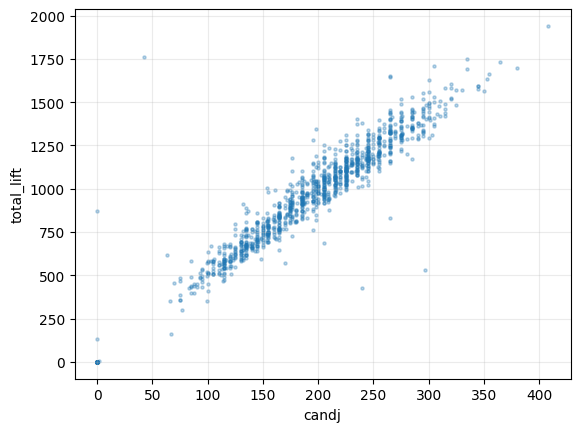

Exact equality share: 0.0064
Suspect: snatch.  Ask: is this value known at prediction time? Is it derived from / recorded after total_lift?


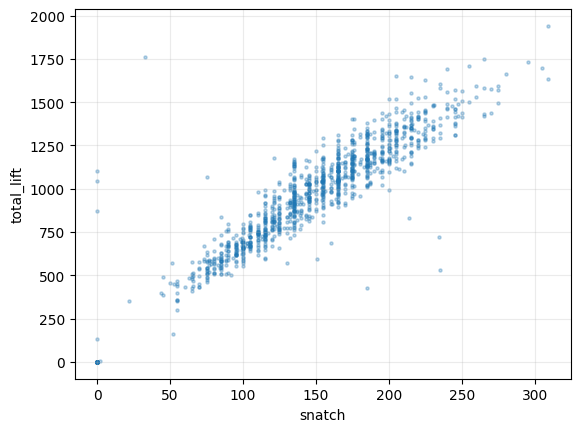

Exact equality share: 0.0064


In [ ]:
for c in [c for c in ['deadlift', 'backsq', 'candj', 'snatch'] if c in df and TARGET]:
    y = df[TARGET]
    print(f"Suspect: {c}.  Ask: is this value known at prediction time? Is it derived from / recorded after {TARGET}?")
    if df[c].nunique() <= 20 or y.nunique() <= 20:
        display(pd.crosstab(df[c], y, normalize="index").round(3).head(15))
    else:
        s = sample(df, 6000); plt.scatter(s[c], s[TARGET], s=5, alpha=.3); plt.xlabel(c); plt.ylabel(TARGET); plt.show()
    if pd.api.types.is_numeric_dtype(df[c]) and pd.api.types.is_numeric_dtype(y): print("Exact equality share:", round((df[c] == y).mean(), 4))

In [ ]:

# Leakage demo: same model, same split, with and without the four lifts
from sklearn.ensemble import HistGradientBoostingRegressor as H
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score
base = ["age", "height", "weight", "is_male", "bmi", "howlong_years"]
for name, cols in {"without lifts": base, "with lifts": base + LIFTS}.items():
    Xtr, Xte, ytr, yte = train_test_split(cdf[cols], cdf.total_lift, test_size=.2, random_state=42)
    print(f"R2 {name}: {r2_score(yte, H(random_state=42).fit(Xtr, ytr).predict(Xte)):.3f}")


R2 without lifts: 0.687


R2 with lifts: 0.998


<a id="F4"></a>
## F4. Gender and weight drive total_lift
**Type:** feature_target &nbsp; **Columns:** `weight`, `gender`

Strongest legitimate predictors; survey flags are weaker. Extra cells rank the v1/v2 features on cleaned data.

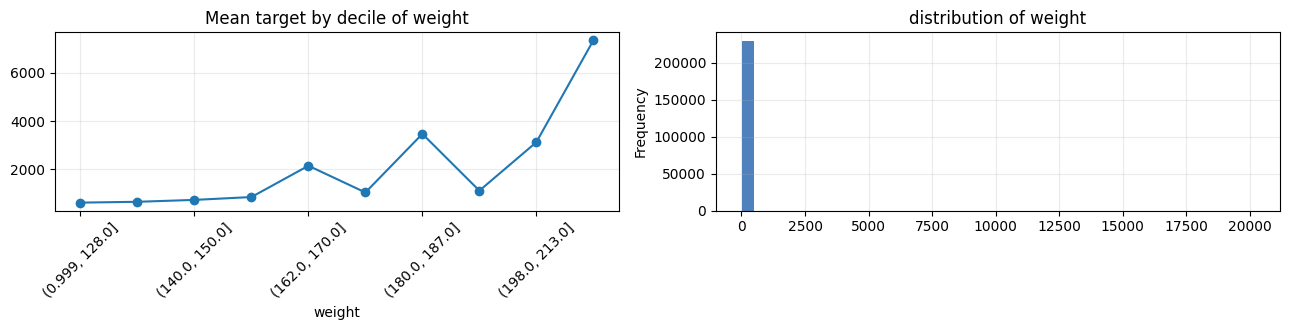

,mean,count
weight,,
"(0.999, 128.0]",625.235,5635
"(128.0, 140.0]",659.500,6842
"(140.0, 150.0]",738.239,6111
"(150.0, 162.0]",856.486,7284
"(162.0, 170.0]",2153.550,7717
"(170.0, 180.0]",1045.666,10015
"(180.0, 187.0]",3474.451,6993
"(187.0, 198.0]",1120.036,9459
"(198.0, 213.0]",3130.468,8511


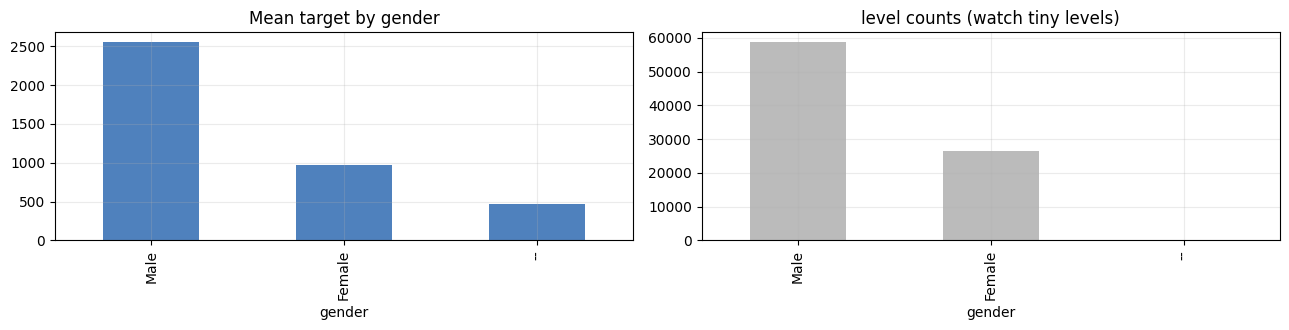

,mean,count
gender,,
Male,2552.617,58701
Female,971.869,26485
--,471.800,5


In [ ]:
for c in [c for c in ['weight', 'gender'] if c in df and TARGET]:
    y = df[TARGET]; yy = y.astype("category").cat.codes.where(y.notna()) if is_cls(y) else y
    fig, axs = plt.subplots(1, 2, figsize=(13, 3.4))
    if c in NUM:
        b = pd.qcut(df[c], 10, duplicates="drop"); g = yy.groupby(b).agg(["mean", "count"])
        g["mean"].plot(ax=axs[0], marker="o"); axs[0].set_title(f"Mean target by decile of {c}"); axs[0].tick_params(axis="x", rotation=45)
        df[c].plot.hist(bins=40, ax=axs[1], color="#4f81bd"); axs[1].set_title(f"distribution of {c}")
    else:
        g = yy.groupby(df[c]).agg(["mean", "count"]).sort_values("count", ascending=False).head(15)
        g["mean"].plot.bar(ax=axs[0], color="#4f81bd"); axs[0].set_title(f"Mean target by {c}")
        g["count"].plot.bar(ax=axs[1], color="#bbbbbb"); axs[1].set_title("level counts (watch tiny levels)")
    plt.tight_layout(); plt.show(); display(g.round(3))

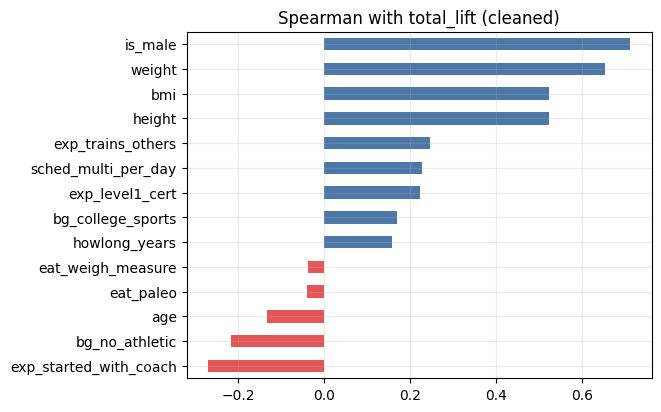

Median total_lift by gender: {'women': 690.0, 'men': 1140.0}


In [ ]:

# Rank the candidate v1/v2 features on the cleaned data (Spearman with total_lift)
cand = ["age","height","weight","is_male","bmi","howlong_years","bg_college_sports","bg_no_athletic","exp_started_with_coach",
        "exp_level1_cert","exp_trains_others","sched_multi_per_day","eat_weigh_measure","eat_paleo"]
a = cdf[cand + ["total_lift"]].corr(method="spearman")["total_lift"].drop("total_lift").sort_values()
a.plot.barh(color=["#e45756" if v < 0 else "#4c78a8" for v in a], figsize=(6, 4.5)); plt.title("Spearman with total_lift (cleaned)"); plt.show()
print("Median total_lift by gender:", cdf.groupby("is_male").total_lift.median().rename({0: "women", 1: "men"}).to_dict())


<a id="F5"></a>
## F5. Kept athletes are not typical (more male)
**Type:** generic &nbsp; **Columns:** n/a

Among athletes with age and gender, 59% male overall vs 73% among the 30,074 kept athletes. Custom cells.

In [ ]:
for c in [c for c in [] if c in df]:
    display(df[c].describe(include="all").to_frame())
    (df[c].dropna().plot.hist(bins=40) if pd.api.types.is_numeric_dtype(df[c]) else df[c].value_counts().head(15)[::-1].plot.barh()); plt.title(c); plt.show()

,athletes with age+gender,kept (cleaned)
n,331054.000,30074.000
male share,0.589,0.727
median age,31.000,31.000


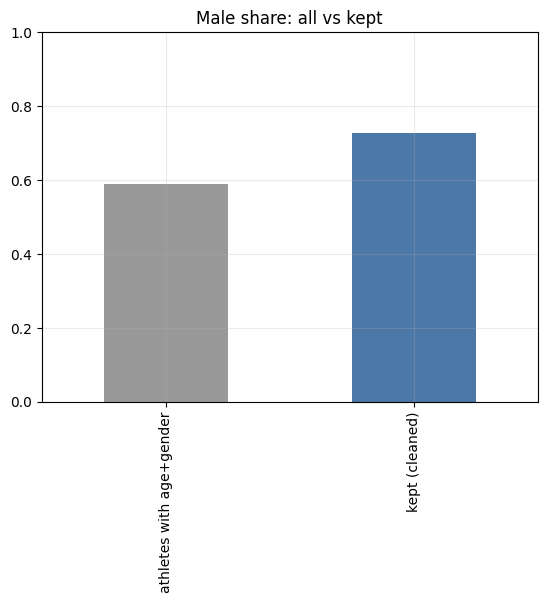

In [ ]:

# Selection bias: compare athletes with age+gender recorded vs the kept (cleaned) athletes
body = raw.dropna(subset=["age", "gender"]); body = body[body.gender.isin(["Male", "Female"])]
kept = body[body.athlete_id.isin(final.athlete_id)]
tab = pd.DataFrame({"athletes with age+gender": [len(body), (body.gender == "Male").mean(), body.age.median()],
                    "kept (cleaned)": [len(kept), (kept.gender == "Male").mean(), kept.age.median()]}, index=["n", "male share", "median age"])
display(tab.round(3))
tab.loc["male share"].plot.bar(color=["#999999", "#4c78a8"]); plt.ylim(0, 1); plt.title("Male share: all vs kept"); plt.show()


<a id="F6"></a>
## F6. 'Started with a coach' is negative, partly a gender confound
**Type:** generic &nbsp; **Columns:** n/a

Negative overall (rho -0.27) and still negative within each gender (-0.09 women, -0.21 men). Custom cells.

In [ ]:
for c in [c for c in [] if c in df]:
    display(df[c].describe(include="all").to_frame())
    (df[c].dropna().plot.hist(bins=40) if pd.api.types.is_numeric_dtype(df[c]) else df[c].value_counts().head(15)[::-1].plot.barh()); plt.title(c); plt.show()

,n,coach_share,spearman_coach_vs_total
is_male,,,
women,8207,0.885,-0.089
men,21867,0.697,-0.210


Overall Spearman: -0.271


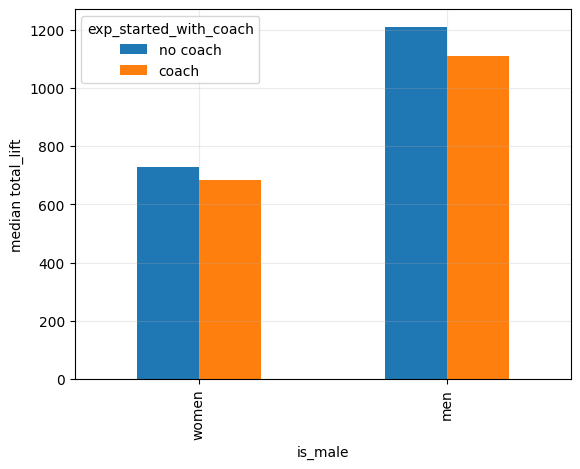

Inference (not proven): gender explains part of the gap, but the sign stays negative within each gender.


In [ ]:

# Simpson/confounder check for 'started with a coach'
g = cdf.groupby("is_male").agg(n=("total_lift", "size"), coach_share=("exp_started_with_coach", "mean"))
g["spearman_coach_vs_total"] = [cdf[cdf.is_male == m][["exp_started_with_coach", "total_lift"]].corr("spearman").iloc[0, 1] for m in g.index]
g.index = g.index.map({0: "women", 1: "men"}); display(g.round(3))
print("Overall Spearman:", round(cdf[["exp_started_with_coach", "total_lift"]].corr("spearman").iloc[0, 1], 3))
cdf.groupby(["is_male", "exp_started_with_coach"]).total_lift.median().unstack().rename(index={0: "women", 1: "men"}, columns={0: "no coach", 1: "coach"}).plot.bar(); plt.ylabel("median total_lift"); plt.show()
print("Inference (not proven): gender explains part of the gap, but the sign stays negative within each gender.")


<a id="F7"></a>
## F7. Tiny lifts survive the cleaning filter
**Type:** generic &nbsp; **Columns:** n/a

22 cleaned rows have a lift under 20 lb (e.g. all four = 1 lb, total = 4). Custom cells; also shows cleaned target distribution.

In [ ]:
for c in [c for c in [] if c in df]:
    display(df[c].describe(include="all").to_frame())
    (df[c].dropna().plot.hist(bins=40) if pd.api.types.is_numeric_dtype(df[c]) else df[c].value_counts().head(15)[::-1].plot.barh()); plt.title(c); plt.show()

cleaned rows with any lift < 20 lb: 22 | rows with total < 200: 18


,deadlift,candj,snatch,backsq,total_lift,weight
3938,1.0,1.0,1.0,1.0,4.0,195.0
26240,1.0,1.0,1.0,1.0,4.0,140.0
29395,1.0,1.0,1.0,1.0,4.0,170.0
13619,2.0,2.0,2.0,2.0,8.0,163.0
14614,2.0,2.0,2.0,2.0,8.0,169.0
24895,2.0,2.0,2.0,2.0,8.0,154.0
949,2.0,1.0,3.0,4.0,10.0,170.0
15100,4.0,2.0,3.0,5.0,14.0,195.0


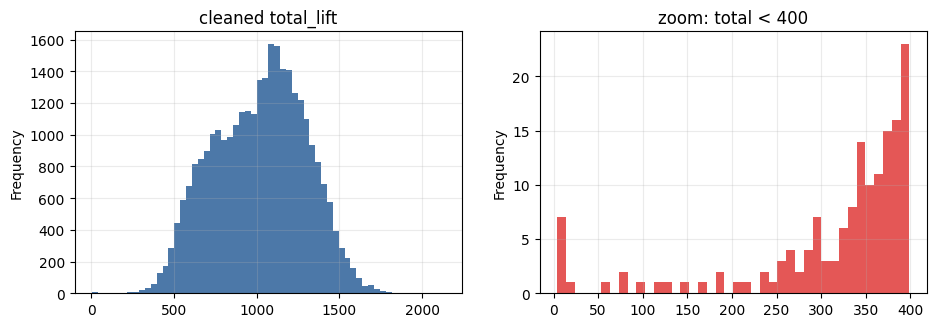

{'count': 30074.0, 'mean': 1017.9, 'std': 277.7, 'min': 4.0, '25%': 805.0, '50%': 1040.0, '75%': 1225.0, 'max': 2135.0} | skew -0.1 | mean-predictor RMSE (= std): 277.7


In [ ]:

# Tiny lifts that pass the 'lift > 0' filter, and the cleaned target
low = cdf[(cdf[LIFTS] < 20).any(axis=1)]
print("cleaned rows with any lift < 20 lb:", len(low), "| rows with total < 200:", int((cdf.total_lift < 200).sum()))
display(low.nsmallest(8, "total_lift")[LIFTS + ["total_lift", "weight"]])
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4)); cdf.total_lift.plot.hist(bins=60, ax=ax[0], color="#4c78a8"); ax[0].set_title("cleaned total_lift")
cdf.total_lift[cdf.total_lift < 400].plot.hist(bins=40, ax=ax[1], color="#e45756"); ax[1].set_title("zoom: total < 400"); plt.show()
print(cdf.total_lift.describe().round(1).to_dict(), "| skew", round(cdf.total_lift.skew(), 2), "| mean-predictor RMSE (= std):", round(cdf.total_lift.std(), 1))


<a id="F8"></a>
## F8. Null and duplicate athlete ids
**Type:** key &nbsp; **Columns:** `athlete_id`

3 null ids and 2 duplicated ids; duplicates are identical rows.

In [ ]:
if ID_COL:
    dk = df[df[ID_COL].duplicated(keep=False)].sort_values(ID_COL)
    print(f"Rows sharing a key: {len(dk)}"); display(dk.head(15))
    nun = dk.groupby(ID_COL).nunique(dropna=False).gt(1).sum().sort_values(ascending=False)
    print("Columns whose values differ within the same key (what actually conflicts):"); display(nun[nun > 0].head(10).to_frame("keys with conflict"))

Rows sharing a key: 3


,athlete_id,region,team,affiliate,gender,age,height,weight,fran,helen,grace,filthy50,fgonebad,run400,run5k,candj,snatch,deadlift,backsq,pullups,eat,train,background,experience,schedule,howlong,total_lift
356779,NaN,None,None,None,None,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None,None,None,None,None,None,NaN
405575,NaN,None,None,None,None,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None,None,None,None,None,None,NaN
417403,NaN,None,None,None,None,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None,None,None,None,None,None,NaN


Columns whose values differ within the same key (what actually conflicts):


,keys with conflict


<a id="F9"></a>
## F9. Survey answers are messy multi-select text
**Type:** category_variants &nbsp; **Columns:** `experience`, `schedule`

83-134 distinct combinations joined by '|'; turned into yes/no flags for v2.

In [ ]:
for c in [c for c in ['experience', 'schedule'] if c in df]:
    raw = df[c].astype(str).value_counts(); norm = df[c].astype(str).str.strip().str.lower().value_counts()
    print(f"{c}: {len(raw)} raw levels -> {len(norm)} after strip+lower"); display(raw.head(15).to_frame("raw count"))

experience: 85 raw levels -> 85 after strip+lower


,raw count
experience,
None,318070
I began CrossFit with a coach (e.g. at an affiliate)|,50695
I began CrossFit with a coach (e.g. at an affiliate)|I have had a life changing experience due to CrossFit|,13560
I began CrossFit by trying it alone (without a coach)|,7778
I began CrossFit with a coach (e.g. at an affiliate)|I have completed the CrossFit Level 1 certificate course|I have attended one or more specialty courses|I have had a life changing experience due to CrossFit|I train other people|,3043
I began CrossFit with a coach (e.g. at an affiliate)|I have completed the CrossFit Level 1 certificate course|I have had a life changing experience due to CrossFit|I train other people|,2357
I began CrossFit with a coach (e.g. at an affiliate)|I have completed the CrossFit Level 1 certificate course|I train other people|,2156
I began CrossFit with a coach (e.g. at an affiliate)|I have completed the CrossFit Level 1 certificate course|,2129
I have had a life changing experience due to CrossFit|,1955


schedule: 135 raw levels -> 135 after strip+lower


,raw count
schedule,
None,325131
I usually only do 1 workout a day|,26688
I usually only do 1 workout a day|I typically rest 4 or more days per month|,19575
I do multiple workouts in a day 3+ times a week|,7078
I typically rest 4 or more days per month|,5099
I do multiple workouts in a day 3+ times a week|I typically rest 4 or more days per month|,3672
I do multiple workouts in a day 2x a week|,3101
I usually only do 1 workout a day|I strictly schedule my rest days|,2990
I do multiple workouts in a day 2x a week|I typically rest 4 or more days per month|,2619


## Appendix
Seed is fixed (`SEED`). Edit the parameter cell to point at a different file or target. Add your own cells under any finding to extend the analysis.